In [1]:
# Cellule 1 - Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import math
import os

warnings.filterwarnings('ignore')
os.makedirs('models', exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             confusion_matrix,
                             balanced_accuracy_score,
                             f1_score,
                             matthews_corrcoef)

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))
print('Imports OK')

TensorFlow : 2.20.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Imports OK


In [2]:
# Cellule 2 - Chargement depuis Google Drive
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/UCI HAR Dataset'

# Features avec noms uniques
with open(f'{BASE}/features.txt') as f:
    features_raw = [line.strip().split(' ', 1)[1] for line in f.readlines()]

seen = {}
features_unique = []
for feat in features_raw:
    if feat in seen:
        seen[feat] += 1
        features_unique.append(feat + '_' + str(seen[feat]))
    else:
        seen[feat] = 0
        features_unique.append(feat)

print('Features uniques :', len(features_unique))

X_train_raw = pd.read_csv(
    f'{BASE}/train/X_train.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)
X_test_raw = pd.read_csv(
    f'{BASE}/test/X_test.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)

y_train_raw = pd.read_csv(f'{BASE}/train/y_train.txt', header=None)[0]
y_test_raw  = pd.read_csv(f'{BASE}/test/y_test.txt',   header=None)[0]

print('X_train_raw :', X_train_raw.shape)
print('X_test_raw  :', X_test_raw.shape)
print('Donnees chargees')

Mounted at /content/drive
Features uniques : 561
X_train_raw : (7352, 561)
X_test_raw  : (2947, 561)
Donnees chargees


In [3]:
# Cellule 3 - Preprocessing + Reshape 64x9
CLASS_NAMES = ['LAYING', 'SITTING', 'STANDING', 'WALKING',
               'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']

le          = LabelEncoder()
y_train     = le.fit_transform(y_train_raw)
y_test      = le.transform(y_test_raw)
NUM_CLASSES = len(le.classes_)
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw.values)
X_test  = scaler.transform(X_test_raw.values)

# Reshape 64x9 = 576 (pad 15 zeros)
target     = 576
pad        = target - X_train.shape[1]
X_train_p  = np.pad(X_train, ((0,0),(0,pad)), mode='constant')
X_test_p   = np.pad(X_test,  ((0,0),(0,pad)), mode='constant')
X_train_3d = X_train_p.reshape(X_train_p.shape[0], 64, 9)
X_test_3d  = X_test_p.reshape(X_test_p.shape[0],   64, 9)

print('X_train_3d  :', X_train_3d.shape)
print('X_test_3d   :', X_test_3d.shape)
print('NUM_CLASSES :', NUM_CLASSES)
print('Preprocessing OK')

X_train_3d  : (7352, 64, 9)
X_test_3d   : (2947, 64, 9)
NUM_CLASSES : 6
Preprocessing OK


In [4]:
# Cellule 4 - Callbacks + LR Schedule
def cosine_warmup_lr(epoch, lr, warmup=10, total=100,
                     min_lr=1e-5, max_lr=1e-3):
    if epoch < warmup:
        return max_lr * (epoch + 1) / warmup
    progress = (epoch - warmup) / (total - warmup)
    return min_lr + 0.5*(max_lr - min_lr)*(1 + math.cos(math.pi * progress))

def get_callbacks(model_name, patience=15):
    return [
        EarlyStopping(
            monitor='val_accuracy',
            patience=patience,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.LearningRateScheduler(
            lambda epoch, lr: cosine_warmup_lr(epoch, lr),
            verbose=0
        ),
        keras.callbacks.ModelCheckpoint(
            filepath='models/' + model_name + '_best.keras',
            monitor='val_accuracy',
            save_best_only=True,
            verbose=0
        )
    ]

print('Callbacks OK')

Callbacks OK


In [5]:
# Cellule 5 - Fonctions utilitaires
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='Val',   color='coral')
    axes[0].set_title(model_name + ' - Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(history.history['loss'],     label='Train', color='steelblue')
    axes[1].plot(history.history['val_loss'], label='Val',   color='coral')
    axes[1].set_title(model_name + ' - Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('models/' + model_name + '_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

def evaluate_model(model, X_input, y_int, model_name):
    y_pred   = np.argmax(model.predict(X_input, verbose=0), axis=1)
    acc      = accuracy_score(y_int, y_pred)
    bal_acc  = balanced_accuracy_score(y_int, y_pred)
    macro_f1 = f1_score(y_int, y_pred, average='macro')
    mcc      = matthews_corrcoef(y_int, y_pred)
    print('=' * 55)
    print('  ' + model_name)
    print('=' * 55)
    print('  Accuracy          :', round(acc*100, 2), '%')
    print('  Balanced Accuracy :', round(bal_acc, 4))
    print('  Macro F1          :', round(macro_f1, 4))
    print('  MCC               :', round(mcc, 4))
    print('=' * 55)
    print(classification_report(y_int, y_pred, target_names=CLASS_NAMES))
    cm = confusion_matrix(y_int, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(model_name + ' - Confusion Matrix', fontsize=12, fontweight='bold')
    plt.ylabel('Reel')
    plt.xlabel('Predit')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig('models/' + model_name + '_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()
    return {
        'Modele'            : model_name,
        'Accuracy'          : round(acc, 4),
        'Balanced_Accuracy' : round(bal_acc, 4),
        'Macro_F1'          : round(macro_f1, 4),
        'MCC'               : round(mcc, 4)
    }

results = []
print('Fonctions OK')

Fonctions OK


In [6]:
# Cellule 6 - Architecture Transformer Encoder
def transformer_block(x, num_heads, ff_dim, d_model, dropout=0.1):
    # Multi-Head Self-Attention + Add & Norm
    attn_out = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )(x, x)
    attn_out = layers.Dropout(dropout)(attn_out)
    x        = layers.LayerNormalization(epsilon=1e-6)(x + attn_out)

    # Feed-Forward Network + Add & Norm
    ff_out = layers.Dense(ff_dim, activation='relu')(x)
    ff_out = layers.Dense(d_model)(ff_out)
    ff_out = layers.Dropout(dropout)(ff_out)
    x      = layers.LayerNormalization(epsilon=1e-6)(x + ff_out)
    return x


def build_transformer(input_shape, num_classes,
                      d_model=128, num_heads=8,
                      ff_dim=256, num_blocks=4,
                      dropout=0.1):
    inputs = keras.Input(shape=input_shape, name='input')

    # Projection initiale
    x = layers.Dense(d_model, name='projection')(inputs)

    # Positional Encoding learnable
    seq_len   = input_shape[0]
    positions = tf.range(start=0, limit=seq_len, delta=1)
    pos_emb   = layers.Embedding(
        input_dim=seq_len,
        output_dim=d_model,
        name='positional_encoding'
    )(positions)
    x = x + pos_emb
    x = layers.Dropout(dropout)(x)

    # 4 blocs Transformer
    for i in range(num_blocks):
        x = transformer_block(x, num_heads, ff_dim, d_model, dropout)

    # Global Average Pooling
    x = layers.GlobalAveragePooling1D()(x)

    # Classifieur
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64,  activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = Model(inputs, outputs, name='Transformer_Encoder')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=['accuracy']
    )
    return model


transformer = build_transformer(
    input_shape=X_train_3d.shape[1:],
    num_classes=NUM_CLASSES
)
transformer.summary()
print('Total parametres :', transformer.count_params())

Model: "Transformer_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 64, 9)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ projection (Dense)  │ (None, 64, 128)   │      1,280 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 128)   │          0 │ projection[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 128)   │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ dropout[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 128)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 128)   │          0 │ dropout[0][0],    │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 128)   │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64, 128)   │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64, 128)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64, 128)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64, 128)   │     32,896 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64, 128)   │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 128)   │          0 │ layer_normalizat

 Total params: 556,358 (2.12 MB)

 Trainable params: 556,358 (2.12 MB)

 Non-trainable params: 0 (0.00 B)

Total parametres : 556358


In [7]:
# Cellule 7 - Entrainement
history_tr = transformer.fit(
    X_train_3d, y_train_ohe,
    epochs=100,
    batch_size=128,
    validation_data=(X_test_3d, y_test_ohe),
    callbacks=get_callbacks('Transformer'),
    verbose=1
)

best_epoch   = np.argmax(history_tr.history['val_accuracy']) + 1
total_epochs = len(history_tr.history['val_accuracy'])
best_val_acc = max(history_tr.history['val_accuracy'])

print('=' * 45)
print('Epochs total      :', total_epochs)
print('Meilleure epoch   :', best_epoch)
print('Meilleure val_acc :', round(best_val_acc, 4))
print('Pour le paper     : epochs =', best_epoch)
print('=' * 45)

Epoch 1/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 41s 294ms/step - accuracy: 0.3451 - loss: 1.5080 - val_accuracy: 0.4567 - val_loss: 1.2563 - learning_rate: 1.0000e-04
Epoch 2/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5231 - loss: 1.2245 - val_accuracy: 0.6736 - val_loss: 1.0058 - learning_rate: 2.0000e-04
Epoch 3/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.6923 - loss: 0.9947 - val_accuracy: 0.7628 - val_loss: 0.8634 - learning_rate: 3.0000e-04
Epoch 4/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7976 - loss: 0.8545 - val_accuracy: 0.8463 - val_loss: 0.7341 - learning_rate: 4.0000e-04
Epoch 5/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.8836 - loss: 0.7027 - val_accuracy: 0.8504 - val_loss: 0.7271 - learning_rate: 5.0000e-04
Epoch 6/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9076 - loss: 0.6550 - val_accuracy: 0.8670 - val_loss: 0.7053 - learning_rate: 6.0000e-04
Epoch 7/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy

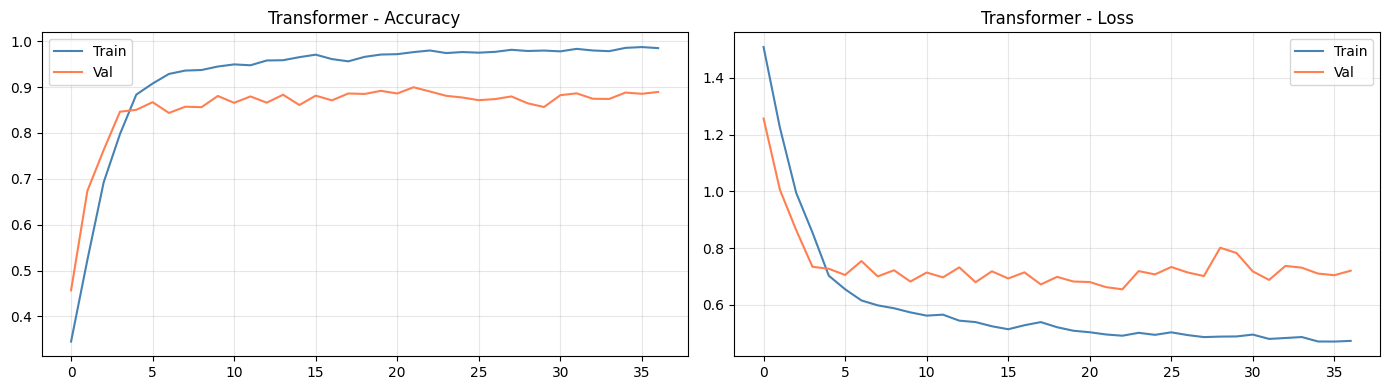

  Transformer
  Accuracy          : 89.96 %
  Balanced Accuracy : 0.8993
  Macro F1          : 0.8984
  MCC               : 0.8796
                    precision    recall  f1-score   support

            LAYING       0.92      0.88      0.90       496
           SITTING       0.89      0.88      0.88       471
          STANDING       0.85      0.92      0.88       420
           WALKING       0.84      0.89      0.86       491
WALKING_DOWNSTAIRS       0.91      0.87      0.89       532
  WALKING_UPSTAIRS       0.98      0.96      0.97       537

          accuracy                           0.90      2947
         macro avg       0.90      0.90      0.90      2947
      weighted avg       0.90      0.90      0.90      2947



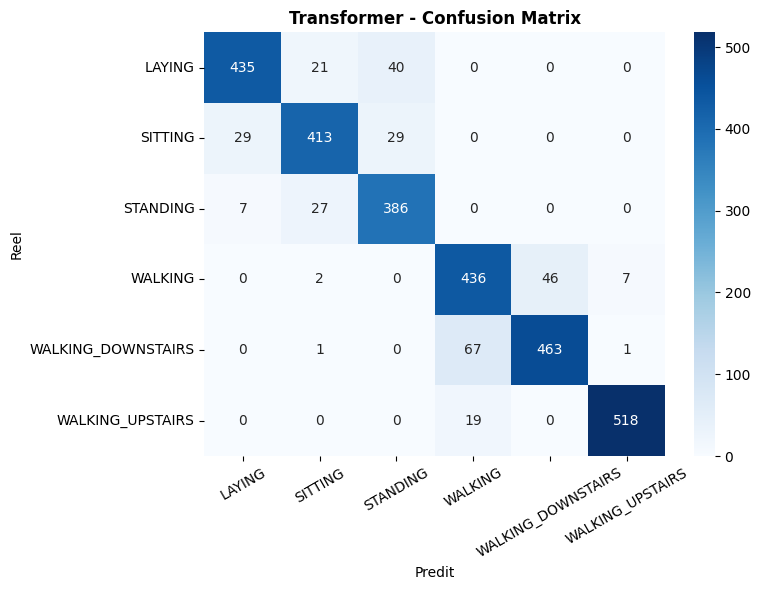

{'Modele': 'Transformer', 'Accuracy': 0.8996, 'Balanced_Accuracy': np.float64(0.8993), 'Macro_F1': 0.8984, 'MCC': np.float64(0.8796)}


In [8]:
# Cellule 8 - Evaluation
plot_history(history_tr, 'Transformer')
res_tr = evaluate_model(transformer, X_test_3d, y_test, 'Transformer')
results.append(res_tr)
print(res_tr)

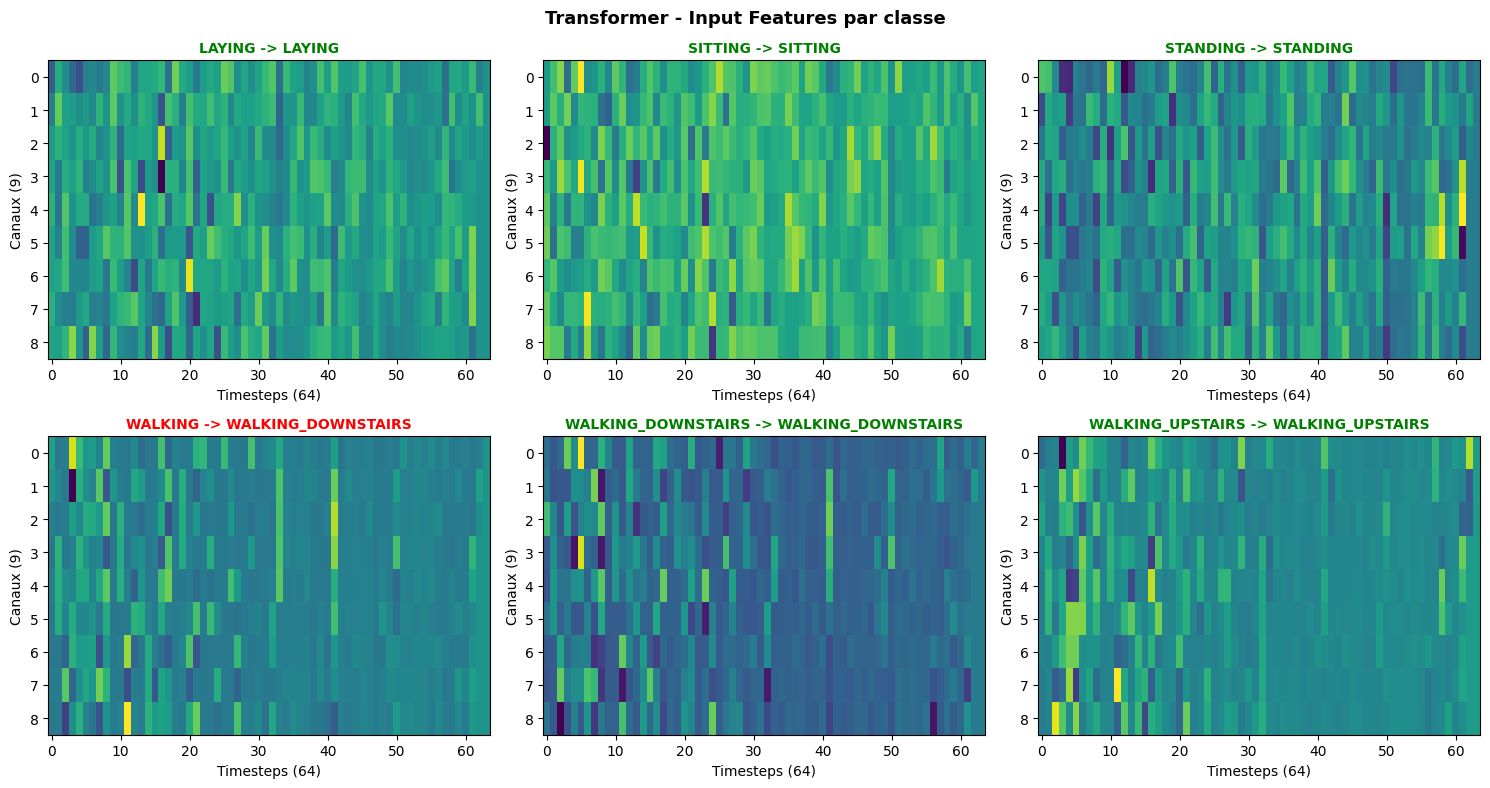

In [9]:
# Cellule 9 - Visualisation Attention (XAI)
# Visualiser les signaux par classe (utile pour le paper)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    idx    = np.where(y_test == cls_idx)[0][0]
    sample = X_test_3d[idx:idx+1]
    pred   = np.argmax(transformer.predict(sample, verbose=0))

    axes[cls_idx].imshow(sample[0].T, aspect='auto', cmap='viridis')
    title = cls_name + ' -> ' + CLASS_NAMES[pred]
    color = 'green' if pred == cls_idx else 'red'
    axes[cls_idx].set_title(title, color=color, fontweight='bold', fontsize=10)
    axes[cls_idx].set_xlabel('Timesteps (64)')
    axes[cls_idx].set_ylabel('Canaux (9)')

plt.suptitle('Transformer - Input Features par classe',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('models/Transformer_vis.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Cellule 3 - Preprocessing + Reshape 64x9
CLASS_NAMES = ['LAYING', 'SITTING', 'STANDING', 'WALKING',
               'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']

le          = LabelEncoder()
y_train     = le.fit_transform(y_train_raw)
y_test      = le.transform(y_test_raw)
NUM_CLASSES = len(le.classes_)
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw.values)
X_test  = scaler.transform(X_test_raw.values)

# Reshape 64x9 = 576 (pad 15 zeros)
target     = 576
pad        = target - X_train.shape[1]
X_train_p  = np.pad(X_train, ((0,0),(0,pad)), mode='constant')
X_test_p   = np.pad(X_test,  ((0,0),(0,pad)), mode='constant')
X_train_3d = X_train_p.reshape(X_train_p.shape[0], 64, 9)
X_test_3d  = X_test_p.reshape(X_test_p.shape[0],   64, 9)

print('X_train_3d :', X_train_3d.shape)
print('X_test_3d  :', X_test_3d.shape)
print('NUM_CLASSES:', NUM_CLASSES)
print('Preprocessing OK')

X_train_3d : (7352, 64, 9)
X_test_3d  : (2947, 64, 9)
NUM_CLASSES: 6
Preprocessing OK


In [11]:
# Cellule 4 - Data Augmentation
def mixup(X, y, alpha=0.2, seed=42):
    np.random.seed(seed)
    lam = np.random.beta(alpha, alpha, size=len(X))
    lam = np.maximum(lam, 1 - lam)
    idx = np.random.permutation(len(X))
    X_mix = np.array([lam[i]*X[i] + (1-lam[i])*X[idx[i]] for i in range(len(X))])
    y_mix = np.array([lam[i]*y[i] + (1-lam[i])*y[idx[i]] for i in range(len(y))])
    return X_mix, y_mix

def jitter(X, sigma=0.05, seed=43):
    np.random.seed(seed)
    return X + np.random.normal(0, sigma, X.shape)

def scaling(X, min_s=0.8, max_s=1.2, seed=44):
    np.random.seed(seed)
    s = np.random.uniform(min_s, max_s, (len(X), 1, 1))
    return X * s

def time_warp(X, shift=3, seed=45):
    np.random.seed(seed)
    shifts = np.random.randint(-shift, shift, len(X))
    return np.array([np.roll(X[i], shifts[i], axis=0) for i in range(len(X))])

# Appliquer toutes les augmentations
X_mix,    y_mix    = mixup(X_train_3d, y_train_ohe)
X_jitter           = jitter(X_train_3d)
X_scaled           = scaling(X_train_3d)
X_warped           = time_warp(X_train_3d)

X_aug = np.concatenate([X_train_3d, X_mix, X_jitter, X_scaled, X_warped], axis=0)
y_aug = np.concatenate([y_train_ohe, y_mix, y_train_ohe, y_train_ohe, y_train_ohe], axis=0)

idx_shuffle = np.random.permutation(len(X_aug))
X_aug = X_aug[idx_shuffle]
y_aug = y_aug[idx_shuffle]

print('Train original :', X_train_3d.shape)
print('Train augmente :', X_aug.shape, '(x5 samples)')
print('Augmentation OK')

Train original : (7352, 64, 9)
Train augmente : (36760, 64, 9) (x5 samples)
Augmentation OK


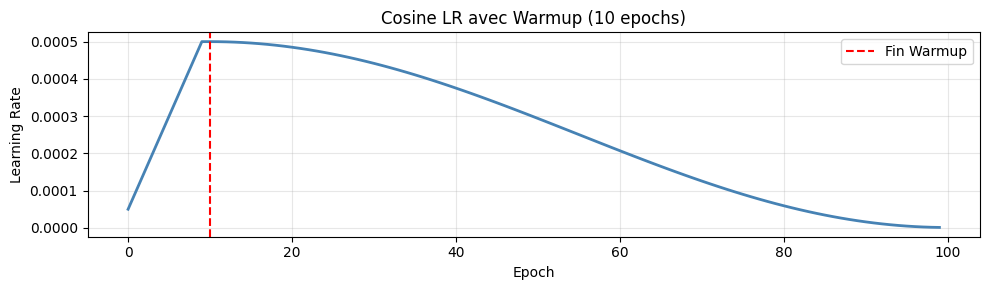

Callbacks OK


In [12]:
# Cellule 5 - Cosine LR + Warmup + Callbacks
def cosine_warmup_lr(epoch, lr, warmup=10, total=100,
                     min_lr=1e-6, max_lr=5e-4):
    if epoch < warmup:
        return max_lr * (epoch + 1) / warmup
    progress = (epoch - warmup) / (total - warmup)
    return min_lr + 0.5*(max_lr - min_lr)*(1 + math.cos(math.pi * progress))

def get_callbacks(model_name, patience=20):
    return [
        EarlyStopping(
            monitor='val_accuracy',
            patience=patience,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.LearningRateScheduler(
            lambda epoch, lr: cosine_warmup_lr(epoch, lr),
            verbose=0
        ),
        keras.callbacks.ModelCheckpoint(
            filepath='models/' + model_name + '_best.keras',
            monitor='val_accuracy',
            save_best_only=True,
            verbose=0
        )
    ]

# Visualiser le LR schedule
lrs = [cosine_warmup_lr(e, 1e-3) for e in range(100)]
plt.figure(figsize=(10, 3))
plt.plot(lrs, color='steelblue', linewidth=2)
plt.title('Cosine LR avec Warmup (10 epochs)')
plt.xlabel('Epoch')
plt.ylabel('Learning Rate')
plt.axvline(x=10, color='red', linestyle='--', label='Fin Warmup')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print('Callbacks OK')

In [13]:
# Cellule 6 - Fonctions utilitaires
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='Val',   color='coral')
    axes[0].set_title(model_name + ' - Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(history.history['loss'],     label='Train', color='steelblue')
    axes[1].plot(history.history['val_loss'], label='Val',   color='coral')
    axes[1].set_title(model_name + ' - Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('models/' + model_name + '_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

def evaluate_model(model, X_input, y_int, model_name):
    y_pred   = np.argmax(model.predict(X_input, verbose=0), axis=1)
    acc      = accuracy_score(y_int, y_pred)
    bal_acc  = balanced_accuracy_score(y_int, y_pred)
    macro_f1 = f1_score(y_int, y_pred, average='macro')
    mcc      = matthews_corrcoef(y_int, y_pred)
    print('=' * 55)
    print('  ' + model_name)
    print('=' * 55)
    print('  Accuracy          :', round(acc*100, 2), '%')
    print('  Balanced Accuracy :', round(bal_acc, 4))
    print('  Macro F1          :', round(macro_f1, 4))
    print('  MCC               :', round(mcc, 4))
    print('=' * 55)
    print(classification_report(y_int, y_pred, target_names=CLASS_NAMES))
    cm = confusion_matrix(y_int, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(model_name + ' - Confusion Matrix', fontsize=12, fontweight='bold')
    plt.ylabel('Reel')
    plt.xlabel('Predit')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig('models/' + model_name + '_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()
    return {
        'Modele'            : model_name,
        'Accuracy'          : round(acc, 4),
        'Balanced_Accuracy' : round(bal_acc, 4),
        'Macro_F1'          : round(macro_f1, 4),
        'MCC'               : round(mcc, 4)
    }

results = []
print('Fonctions OK')

Fonctions OK


In [14]:
# Cellule 7 - Architecture Transformer V2
# Amelioration : CNN Feature Extractor + Transformer plus profond

def transformer_block(x, num_heads, ff_dim, d_model, dropout=0.1):
    # Multi-Head Self-Attention + Add & Norm
    attn_out = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )(x, x)
    attn_out = layers.Dropout(dropout)(attn_out)
    x1 = layers.LayerNormalization(epsilon=1e-6)(x + attn_out)

    # Feed-Forward Network + Add & Norm
    ff_out = layers.Dense(ff_dim, activation='gelu')(x1)  # GELU au lieu de ReLU
    ff_out = layers.Dense(d_model)(ff_out)
    ff_out = layers.Dropout(dropout)(ff_out)
    x2 = layers.LayerNormalization(epsilon=1e-6)(x1 + ff_out)
    return x2


def build_transformer_v2(input_shape, num_classes,
                          d_model=256, num_heads=8,
                          ff_dim=512, num_blocks=6,
                          dropout=0.1):
    inputs = keras.Input(shape=input_shape, name='input')

    # ---- CNN Feature Extractor (nouveau) ----
    # Extrait des features locales avant le Transformer
    x = layers.Conv1D(64,  kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(128, kernel_size=3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.1)(x)

    # ---- Projection vers d_model ----
    x = layers.Dense(d_model, name='projection')(x)

    # ---- Positional Encoding learnable ----
    seq_len   = input_shape[0]
    positions = tf.range(start=0, limit=seq_len, delta=1)
    pos_emb   = layers.Embedding(
        input_dim=seq_len,
        output_dim=d_model,
        name='positional_encoding'
    )(positions)
    x = x + pos_emb
    x = layers.Dropout(dropout)(x)

    # ---- 6 blocs Transformer ----
    for i in range(num_blocks):
        x = transformer_block(x, num_heads, ff_dim, d_model, dropout)

    # ---- Aggregation ----
    # CLS token simulation via GlobalAvgPool + GlobalMaxPool
    x_avg = layers.GlobalAveragePooling1D()(x)
    x_max = layers.GlobalMaxPooling1D()(x)
    x = layers.Concatenate()([x_avg, x_max])   # (d_model*2)

    # ---- Classifieur ----
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64,  activation='relu')(x)
    x = layers.Dropout(0.1)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = Model(inputs, outputs, name='Transformer_V2')
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=5e-4,
            weight_decay=1e-4
        ),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=['accuracy']
    )
    return model


transformer_v2 = build_transformer_v2(
    input_shape=X_train_3d.shape[1:],
    num_classes=NUM_CLASSES
)
transformer_v2.summary()
print('Total parametres :', transformer_v2.count_params())

Model: "Transformer_V2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 64, 9)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 64, 64)    │      1,792 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 64, 128)   │     24,704 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128)   │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 64, 128)   │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ projection (Dense)  │ (None, 64, 256)   │     33,024 │ dropout_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 64, 256)   │          0 │ projection[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 64, 256)   │          0 │ add_9[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ dropout_16[0][0], │
│ (MultiHeadAttentio… │                   │            │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 64, 256)   │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 64, 256)   │          0 │ dropout_16[0][0], │
│                     │                   │            │ dropout_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_10[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 64, 512)   │    131,584 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 64, 256)   │    131,328 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_19          │ (None, 64, 256)   │          0 │ dense_11[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_19[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_11[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat

 Total params: 3,395,782 (12.95 MB)

 Trainable params: 3,395,398 (12.95 MB)

 Non-trainable params: 384 (1.50 KB)

Total parametres : 3395782


In [15]:
# Cellule 8 - Entrainement
history_v2 = transformer_v2.fit(
    X_aug, y_aug,                          # donnees augmentees x5
    epochs=100,
    batch_size=128,
    validation_data=(X_test_3d, y_test_ohe),
    callbacks=get_callbacks('Transformer_V2'),
    verbose=1
)

best_epoch   = np.argmax(history_v2.history['val_accuracy']) + 1
total_epochs = len(history_v2.history['val_accuracy'])
best_val_acc = max(history_v2.history['val_accuracy'])

print('=' * 45)
print('Epochs total      :', total_epochs)
print('Meilleure epoch   :', best_epoch)
print('Meilleure val_acc :', round(best_val_acc, 4))
print('Pour le paper     : epochs =', best_epoch)
print('=' * 45)

Epoch 1/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 98s 201ms/step - accuracy: 0.5704 - loss: 1.2106 - val_accuracy: 0.7089 - val_loss: 0.9352 - learning_rate: 5.0000e-05
Epoch 2/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 30s 103ms/step - accuracy: 0.8615 - loss: 0.7669 - val_accuracy: 0.9074 - val_loss: 0.6241 - learning_rate: 1.0000e-04
Epoch 3/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 30s 104ms/step - accuracy: 0.9471 - loss: 0.6096 - val_accuracy: 0.8928 - val_loss: 0.6654 - learning_rate: 1.5000e-04
Epoch 4/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 29s 100ms/step - accuracy: 0.9679 - loss: 0.5626 - val_accuracy: 0.8918 - val_loss: 0.6648 - learning_rate: 2.0000e-04
Epoch 5/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 30s 103ms/step - accuracy: 0.9786 - loss: 0.5361 - val_accuracy: 0.9097 - val_loss: 0.6459 - learning_rate: 2.5000e-04
Epoch 6/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 30s 104ms/step - accuracy: 0.9826 - loss: 0.5234 - val_accuracy: 0.9216 - val_loss: 0.6089 - learning_rate: 3.0000e-04
Epoch 7/100
288/288 ━━━━━━━━━━━━━━━━━━━━

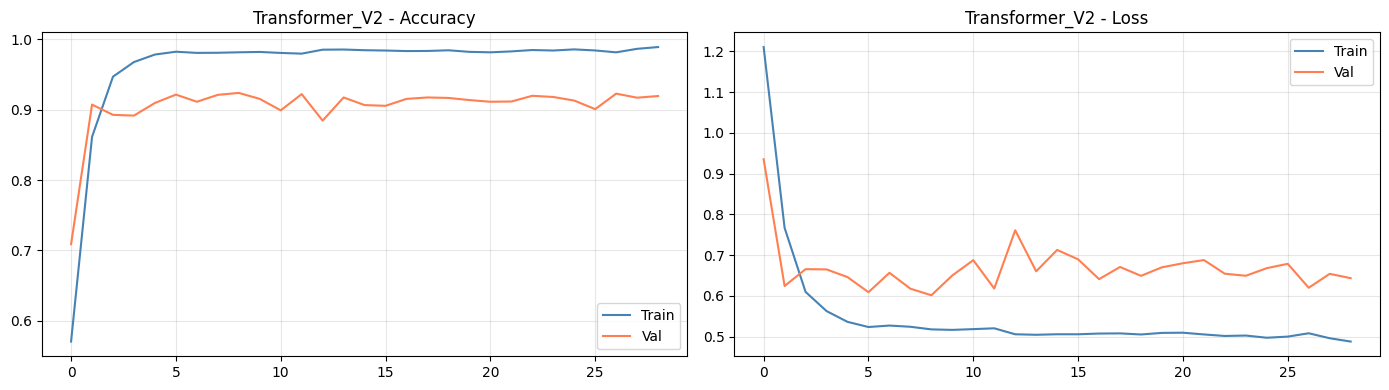

  Transformer V2
  Accuracy          : 92.4 %
  Balanced Accuracy : 0.9242
  Macro F1          : 0.9242
  MCC               : 0.9088
                    precision    recall  f1-score   support

            LAYING       0.92      0.97      0.94       496
           SITTING       0.97      0.89      0.93       471
          STANDING       0.93      0.96      0.94       420
           WALKING       0.86      0.87      0.86       491
WALKING_DOWNSTAIRS       0.88      0.89      0.88       532
  WALKING_UPSTAIRS       0.99      0.97      0.98       537

          accuracy                           0.92      2947
         macro avg       0.93      0.92      0.92      2947
      weighted avg       0.93      0.92      0.92      2947



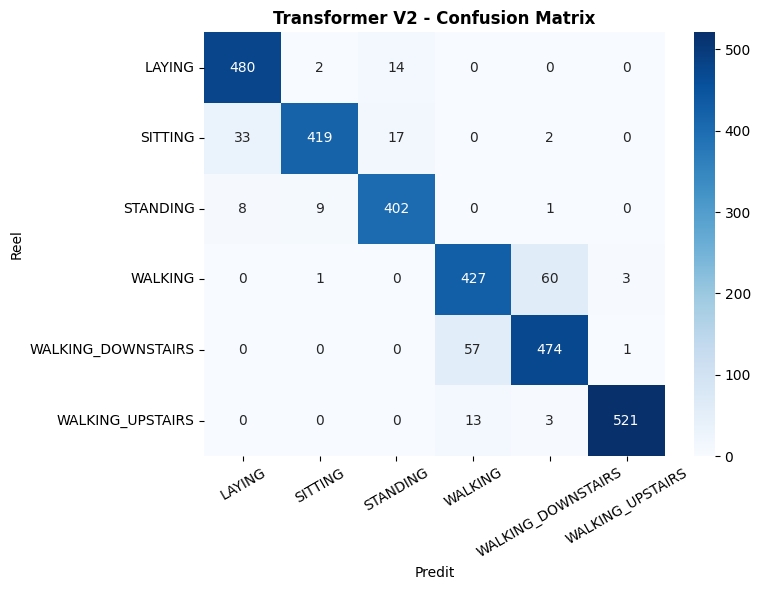

{'Modele': 'Transformer V2', 'Accuracy': 0.924, 'Balanced_Accuracy': np.float64(0.9242), 'Macro_F1': 0.9242, 'MCC': np.float64(0.9088)}


In [16]:
# Cellule 9 - Evaluation
plot_history(history_v2, 'Transformer_V2')
res_v2 = evaluate_model(transformer_v2, X_test_3d, y_test, 'Transformer V2')
results.append(res_v2)
print(res_v2)

       COMPARAISON Transformer V1 vs V2
        Modele  Accuracy  Balanced_Accuracy  Macro_F1    MCC
Transformer V1    0.8996             0.8993    0.8984 0.8796
Transformer V2    0.9240             0.9242    0.9242 0.9088

Ameliorations :
  Accuracy : +2.44%
  Balanced_Accuracy : +2.49%
  Macro_F1 : +2.58%
  MCC : +2.92%


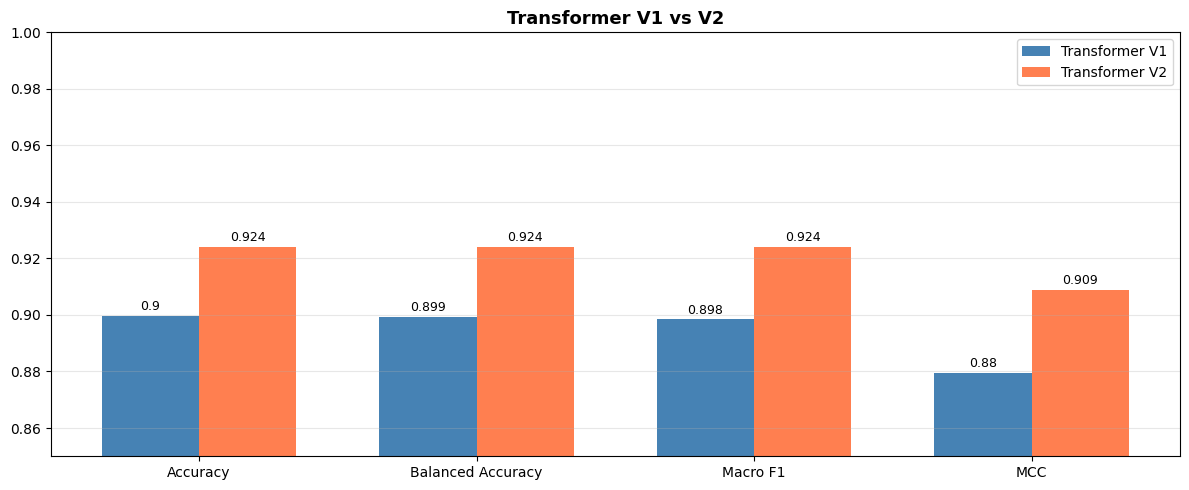

In [17]:
# Cellule 10 - Comparaison V1 vs V2
res_v1 = {
    'Modele'            : 'Transformer V1',
    'Accuracy'          : 0.8996,
    'Balanced_Accuracy' : 0.8993,
    'Macro_F1'          : 0.8984,
    'MCC'               : 0.8796
}

comparison = pd.DataFrame([res_v1, res_v2])

print('=' * 60)
print('       COMPARAISON Transformer V1 vs V2')
print('=' * 60)
print(comparison.to_string(index=False))
print('=' * 60)

metrics = ['Accuracy', 'Balanced_Accuracy', 'Macro_F1', 'MCC']
print('\nAmeliorations :')
for m in metrics:
    delta = res_v2[m] - res_v1[m]
    sign  = '+' if delta >= 0 else ''
    print('  ' + m + ' : ' + sign + str(round(delta*100, 2)) + '%')

# Graphique
x     = np.arange(len(metrics))
width = 0.35
fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, [res_v1[m] for m in metrics],
               width, label='Transformer V1', color='steelblue')
bars2 = ax.bar(x + width/2, [res_v2[m] for m in metrics],
               width, label='Transformer V2', color='coral')
ax.set_title('Transformer V1 vs V2', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([m.replace('_', ' ') for m in metrics])
ax.set_ylim(0.85, 1.0)
ax.legend()
ax.grid(axis='y', alpha=0.3)
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.002,
            str(round(bar.get_height(), 3)), ha='center', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.002,
            str(round(bar.get_height(), 3)), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('models/Transformer_V1_vs_V2.png', dpi=150, bbox_inches='tight')
plt.show()